In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from scipy.cluster.hierarchy import dendrogram,linkage
import matplotlib.pyplot as math
from sklearn.cluster import KMeans



In [ ]:
mall = pd.read_csv("/content/Mall_Customers - Mall_Customers.csv")

mall

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


In [ ]:
mall.isnull().sum()

,0
CustomerID,0
Genre,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


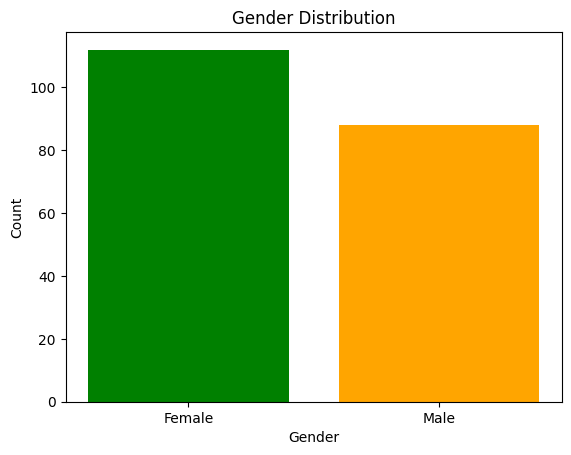

In [ ]:
gender_counts = mall["Genre"].value_counts()
math.bar(gender_counts.index, gender_counts.values, color=['green', 'orange'])
math.xlabel('Gender')
math.ylabel('Count')
math.title('Gender Distribution')
math.show()


In [ ]:
mall.dtypes

,0
CustomerID,int64
Genre,object
Age,int64
Annual Income (k$),int64
Spending Score (1-100),int64


In [ ]:
le = LabelEncoder()

mall["Genre"] = le.fit_transform(mall["Genre"])

In [ ]:
mall

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,1,19,15,39
1,2,1,21,15,81
2,3,0,20,16,6
3,4,0,23,16,77
4,5,0,31,17,40
...,...,...,...,...,...
195,196,0,35,120,79
196,197,0,45,126,28
197,198,1,32,126,74
198,199,1,32,137,18


In [ ]:
model1 = KMeans(3,random_state=0)
model1 = model1.fit(mall[["Annual Income (k$)", "Spending Score (1-100)"]])
model1.cluster_centers_

array([[44.15447154, 49.82926829],
       [86.53846154, 82.12820513],
       [87.        , 18.63157895]])

In [ ]:
model1.predict([[131,84],[267,45]])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


array([1, 2], dtype=int32)

In [ ]:
mall.describe()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000,200.000000
mean,100.500000,0.440000,38.850000,60.560000,50.200000
std,57.879185,0.497633,13.969007,26.264721,25.823522
min,1.000000,0.000000,18.000000,15.000000,1.000000
25%,50.750000,0.000000,28.750000,41.500000,34.750000
50%,100.500000,0.000000,36.000000,61.500000,50.000000
75%,150.250000,1.000000,49.000000,78.000000,73.000000
max,200.000000,1.000000,70.000000,137.000000,99.000000


In [ ]:
mall.isna()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,False,False,False,False,False
1,False,False,False,False,False
2,False,False,False,False,False
3,False,False,False,False,False
4,False,False,False,False,False
...,...,...,...,...,...
195,False,False,False,False,False
196,False,False,False,False,False
197,False,False,False,False,False
198,False,False,False,False,False


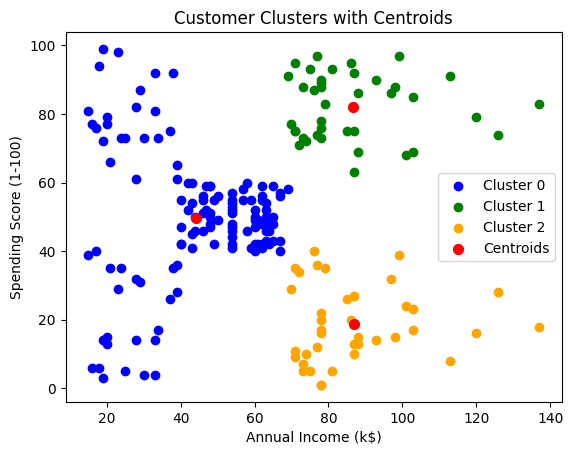

In [ ]:
colors = ['blue', 'green', 'orange']

for i in range(model1.n_clusters):
    math.scatter(
        mall.loc[model1.labels_ == i, "Annual Income (k$)"],
        mall.loc[model1.labels_ == i, "Spending Score (1-100)"],
        c=colors[i],
        label=f'Cluster {i}'
    )

# Centroids
centers = model1.cluster_centers_

math.scatter(
    centers[:, 0],
    centers[:, 1],
    c='red',
    marker='o',
    s=50,
    label='Centroids'
)

math.title('Customer Clusters with Centroids')
math.xlabel('Annual Income (k$)')
math.ylabel('Spending Score (1-100)')
math.legend()

math.show()

In [ ]:
wcss = {}
for i in range(1,11):
    model3 = KMeans(i,random_state=0).fit(mall[["Annual Income (k$)", "Spending Score (1-100)"]])
    wcss[i] = model3.inertia_

print(wcss)

k,v = [],[]

for key,val in wcss.items():
    k.append(key)
    v.append(val)

{1: 269981.28000000014, 2: 185917.1425392853, 3: 106348.37306211119, 4: 73679.78903948837, 5: 44448.45544793369, 6: 38858.959975143895, 7: 31969.42655023547, 8: 29858.48359760394, 9: 22209.851608025536, 10: 20786.936692059153}


In [ ]:
mall.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Genre                   200 non-null    int64
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(5)
memory usage: 7.9 KB


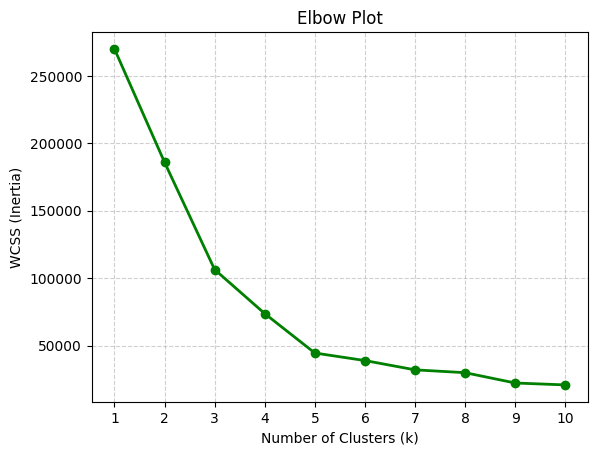

In [ ]:
math.plot(k, v, marker='o', linewidth=2, color='green')
math.xticks(range(1, 11))

math.title('Elbow Plot')
math.xlabel('Number of Clusters (k)')
math.ylabel('WCSS (Inertia)')

math.grid(True, linestyle='--', alpha=0.6)
math.show()


In [ ]:
#From the graph we can say that K = 5

model2 = KMeans(5,random_state=0)
model2 = model2.fit(mall[["Annual Income (k$)", "Spending Score (1-100)"]])
model2.cluster_centers_

array([[55.2962963 , 49.51851852],
       [86.53846154, 82.12820513],
       [88.2       , 17.11428571],
       [26.30434783, 20.91304348],
       [25.72727273, 79.36363636]])

In [ ]:
model2.predict([[131,84],[267,45]])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


array([1, 2], dtype=int32)

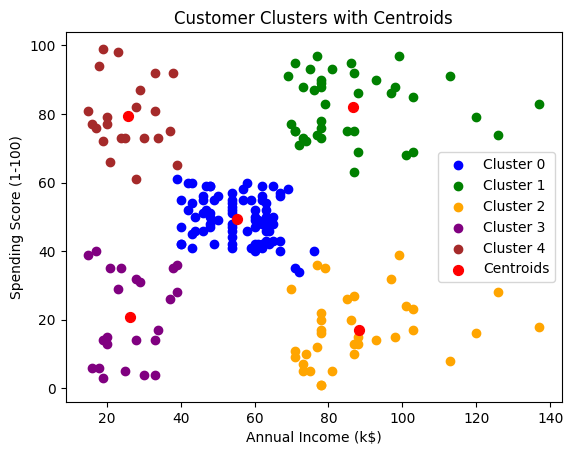

In [ ]:
colors = ['blue', 'green', 'orange', 'purple', 'brown']

for i in range(model2.n_clusters):
    math.scatter(
        mall.loc[model2.labels_ == i, "Annual Income (k$)"],
        mall.loc[model2.labels_ == i, "Spending Score (1-100)"],
        c=colors[i],
        label=f'Cluster {i}'
    )

# Centroids
centers = model2.cluster_centers_

math.scatter(
    centers[:, 0],
    centers[:, 1],
    c='red',
    marker='o',
    s=50,
    label='Centroids'
)

math.title('Customer Clusters with Centroids')
math.xlabel('Annual Income (k$)')
math.ylabel('Spending Score (1-100)')
math.legend()

math.show()

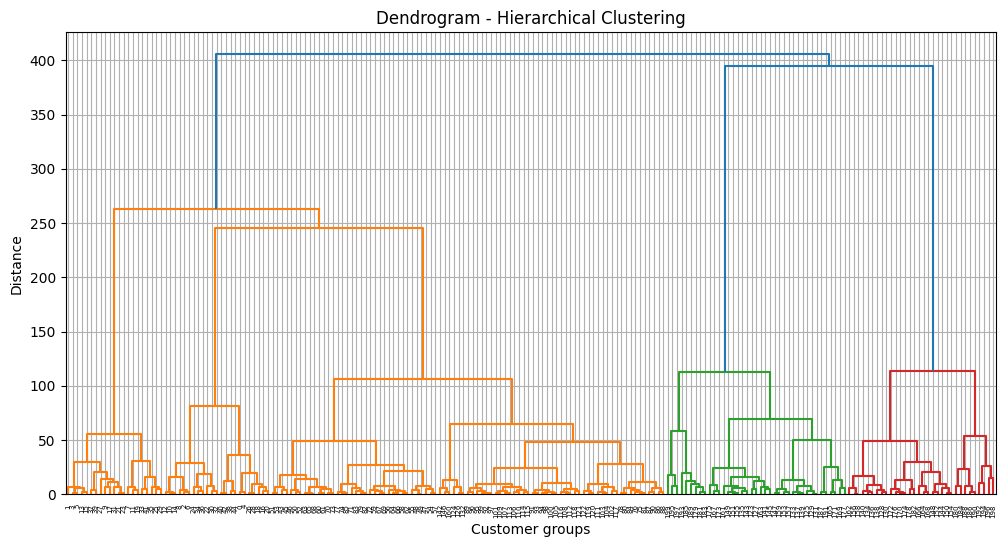

In [ ]:
from scipy.cluster.hierarchy import linkage, dendrogram
import seaborn as sns

Z = linkage(mall[["Annual Income (k$)", "Spending Score (1-100)"]], method="ward")

math.figure(figsize=(12, 6))
dendrogram(Z)

math.title("Dendrogram - Hierarchical Clustering")
math.xlabel("Customer groups")
math.ylabel("Distance")
math.grid()
math.show()

In [ ]:
personal = {"c_id": int(input("Enter customer ID: ")),
           "gender": (input("Enter gender(M/F): ")),
           "age": int(input("Enter age: "))}

financial = {"Annual Income (k$)": int(input("Enter Annual Income(k$): ")),
           "Spending Score (1-100)": int(input("Enter Spending Score(1-100): "))}

user_frame = pd.DataFrame([financial])

predicted = model2.predict(user_frame)

print(f"{personal} {financial}\nPredicted Catergorie: {predicted}")

Enter customer ID: 45
Enter gender(M/F): F
Enter age: 25
Enter Annual Income(k$): 38
Enter Spending Score(1-100): 68
{'c_id': 45, 'gender': 'F', 'age': 25} {'Annual Income (k$)': 38, 'Spending Score (1-100)': 68}
Predicted Catergorie: [4]


<Figure size 2000x1200 with 0 Axes>

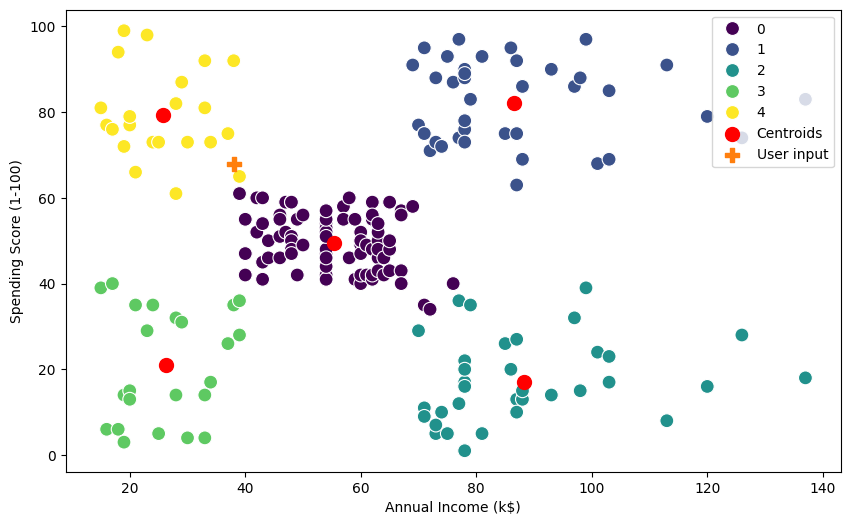

<Figure size 2000x1200 with 0 Axes>

In [ ]:
math.figure(figsize=(10, 6))
sns.scatterplot(x=mall["Annual Income (k$)"],y=mall["Spending Score (1-100)"],hue=model2.labels_,palette="viridis",s=100)

math.scatter(model2.cluster_centers_[:,0],model2.cluster_centers_[:,1],s=100,c='red',label="Centroids")
math.scatter(user_frame["Annual Income (k$)"],user_frame["Spending Score (1-100)"],marker='P',label="User input",s=100)

math.legend(loc="upper right")
math.figure(figsize=(20, 12))

In [ ]:
mall

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,1,19,15,39
1,2,1,21,15,81
2,3,0,20,16,6
3,4,0,23,16,77
4,5,0,31,17,40
...,...,...,...,...,...
195,196,0,35,120,79
196,197,0,45,126,28
197,198,1,32,126,74
198,199,1,32,137,18
